# Aggregating results

### Setting and Functions

In [2]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.dates as mdates
import matplotlib
import seaborn as sns
import numpy as np
import pandas as pd
import glob
import os,sys,json
import pickle
import warnings
from datetime import datetime, timedelta
from tableone import TableOne
warnings.filterwarnings('ignore')

working_dir = os.path.abspath("")
sys.path.append(working_dir)
# custom utils
from funcs.utils import *
from funcs.feat_funcs import *
from funcs.metric_funcs import *
custom_palette = ["#5F6C7B", "#368899", "#E03F67", "#F47C6D"]
sns.set_palette(custom_palette)
# my_palette = sns.color_palette(custom_palette)
matplotlib.rcParams['font.weight'] = 'light'

data_folder = '../data'
metadata_file = f'{data_folder}/patient_meta_info.csv'
metadata = pd.read_csv(metadata_file)

metric_labels = {'auroc_sample':'AUROC',
                  'auprc_sample':'AUPRC',
                  'recall_event':'Seizure Detected, %', # 1-miss
                  'recall_sample':'Seizure Sample Detected, %', # total_sz_dura-miss_min
                  'tn':'Specificity, %', 
                   'precision_event':'Precision, %',
                   'precision_sample':'Precision Sample, %',
                   'fp':'False Alarm/h',
                   'f1_event':'F1 Score',
                   'f1_sample':'F1 Sample',
                   'balanced_acc':'Balanced Accuracy',
                   'mcc':'MCC'}

plot_vars = ['auroc_sample','auprc_sample','recall_event','f1_event','fp']
plot_labels = [metric_labels[k] for k in plot_vars]

ieeg_list = ['PID009','PID016'] # ieeg patients
patient_order = metadata['PID'].tolist() # included patients in order
out_dir = '../manuscript' # output directory
os.makedirs(out_dir, exist_ok=True)
patient_rank = {v: i for i, v in enumerate(patient_order)}

In [3]:
def plot_paired_line(df1, df2, variables=None, figsize=(15, 6), save_path=None, ieeg=True, ieeg_col='patient'):
    if variables is None:
        variables = df1.columns.tolist()
    fig, axes = plt.subplots(1, len(variables), sharey=True, figsize=figsize, sharex=False)
    if len(variables) == 1:
        axes = [axes]  # make iterable
    ax2 = axes[-1].twinx()
    for ax, var in zip(axes, variables):
        if var == 'fp':
            ax = ax2
        # Plot individual subjects
        for i in range(len(df1)):
            if ieeg:
                if df1[ieeg_col].iloc[i] in ieeg_list:
                    ax.plot([0, 1], [df1[var].iloc[i], df2[var].iloc[i]], 
                            color='#C01711', linewidth=1)
                else:
                    ax.plot([0, 1], [df1[var].iloc[i], df2[var].iloc[i]], 
                            color='k', linewidth=1)
            else:
                ax.plot([0, 1], [df1[var].iloc[i], df2[var].iloc[i]], 
                        color='k', linewidth=1)
            ax.plot([0], [df1[var].iloc[i]], 
                    markerfacecolor='white',    # inside color
                    markeredgecolor="#368899",  # border color
                    markeredgewidth=1.5,
                    marker="o")
            ax.plot([1], [df2[var].iloc[i]], 
                    markerfacecolor='white',    # inside color
                    markeredgecolor="#E03F67",  # border color
                    markeredgewidth=1.5,
                    marker="o")
        ax.set_xticks([0,1])
        ax.set_xticklabels(['Baseline','Fine-tuned'], rotation=45)
        ax2.set_xticklabels(['Baseline','Fine-tuned'], rotation=45)
        ax.set_title(metric_labels[var])
        ax.set_xlim((-0.3,1.3))
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path+'.svg', dpi=300)
        plt.close(fig)

def plot_mean_diff_overlay(long_df, sep_axis_fp = False, color = None, variables = None, ieeg=False, ieeg_col='patient', ieeg_color=None, ylims=None):

    if color is None:
        color = '#2A6F97'
    if ieeg and ieeg_color is None:
        ieeg_color = '#C01711'
    if ylims is None:
        ylims = {}
    if variables is None:
        variables = plot_vars
        labels = plot_labels
    else:
        labels = [metric_labels[v] for v in variables]
    long_df = long_df[long_df['metric'].isin(variables)]
    n_metric = len(variables)
    fig, ax = plt.subplots(1,n_metric, figsize=(10, 5), sharey=True)
    for e,metric in enumerate(variables):
        if metric == 'fp':
            if sep_axis_fp:
                ax2 = ax[e].twinx()
                ax_use = ax2
            else:
                ax_use = ax[e]
        else:
            ax_use = ax[e]
        ylim = ylims.get(metric,None)
        sns.boxplot(
            y='value',
            data=long_df[long_df['metric']==metric],
            color='black',
            notch=False, showcaps=True,showfliers=False,
            width=0.6,
            boxprops={"facecolor": "white","edgecolor":"black"},
            medianprops={"color": "black", "linewidth": 2},
            ax=ax_use
        )
        if not ieeg:
            sns.stripplot(
                y='value',
                jitter = 0.06,
                data=long_df[long_df['metric']==metric],
                size=7,
                alpha = 1,
                legend=False,zorder=100,color = color,
                ax = ax_use
            )
        else:
            sns.stripplot(
                y='value',
                jitter = 0.06,
                data=long_df[(long_df['metric']==metric)&(~long_df[ieeg_col].isin(ieeg_list))],
                size=7,
                alpha = 1,
                legend=False,zorder=100,color = color,
                ax = ax_use
            )
            sns.stripplot(
                y='value',
                jitter = 0.06,
                data=long_df[(long_df['metric']==metric)&(long_df[ieeg_col].isin(ieeg_list))],
                size=7,
                alpha = 0.6,
                legend=False,zorder=100,color = ieeg_color,
                ax = ax_use
            )
        ax_use.hlines([0],xmin=-1,xmax=1,linestyle='--',color='gray',linewidth=1,zorder=0)
        ax_use.legend().remove()
        ax_use.set_xlabel('')
        ax_use.set_ylabel('')
        ax_use.set_title(labels[e],fontsize=12)
        if ylim is not None:
            ax_use.set_ylim(ylim)
        ax_use.set_xticks(ticks=[0], labels=['Delta'],fontsize=12, rotation=25)
    return fig, ax

def bootstrap_ci(
    values,
    clusters=None,
    n_boot: int = 1000,
    ci: float = 95,
    seed: int = 42,
):
    """Return the sample mean and a percentile bootstrap CI for the mean.

    If clusters is provided, resample whole clusters with replacement.
    """
    frame = pd.DataFrame({"value": np.asarray(values, dtype=float)})
    if clusters is not None:
        frame["cluster"] = np.asarray(clusters)
    frame = frame.dropna()

    if frame.empty:
        return np.nan, np.nan, np.nan

    mean = float(frame["value"].mean())
    if len(frame) == 1:
        return mean, mean, mean

    rng = np.random.default_rng(seed)
    boot_means = np.empty(n_boot, dtype=float)

    if clusters is None:
        sample_values = frame["value"].to_numpy()
        for index in range(n_boot):
            boot_means[index] = rng.choice(
                sample_values,
                size=len(sample_values),
                replace=True,
            ).mean()
    else:
        cluster_values = {
            cluster: group["value"].to_numpy()
            for cluster, group in frame.groupby("cluster", sort=False)
        }
        cluster_ids = np.fromiter(cluster_values.keys(), dtype=object)
        for index in range(n_boot):
            sampled_clusters = rng.choice(
                cluster_ids,
                size=len(cluster_ids),
                replace=True,
            )
            boot_sample = np.concatenate(
                [cluster_values[cluster] for cluster in sampled_clusters]
            )
            boot_means[index] = boot_sample.mean()

    alpha = (100 - ci) / 2
    ci_lower = float(np.percentile(boot_means, alpha))
    ci_upper = float(np.percentile(boot_means, 100 - alpha))
    return mean, ci_lower, ci_upper


def summarize_series(
    values,
    clusters=None,
    n_boot: int = 1000,
    ci: float = 95,
    seed: int = 42,
):
    """Summary statistics for one numeric sample."""
    series = pd.Series(values, dtype=float).dropna()
    if series.empty:
        return pd.Series(
            {
                "n": 0,
                "mean": np.nan,
                "std": np.nan,
                "median": np.nan,
                "iqr": np.nan,
                "ci_lower": np.nan,
                "ci_upper": np.nan,
            }
        )

    cluster_values = None
    if clusters is not None:
        cluster_values = pd.Series(clusters, index=series.index).loc[series.index]

    mean, ci_lower, ci_upper = bootstrap_ci(
        series.to_numpy(),
        clusters=None if cluster_values is None else cluster_values.to_numpy(),
        n_boot=n_boot,
        ci=ci,
        seed=seed,
    )

    tmp = pd.Series(
        {
            "n": int(series.shape[0]),
            "mean": mean,
            "std": float(series.std(ddof=1)),
            "median": float(series.median()),
            "q1": float(series.quantile(0.25)),
            "q3": float(series.quantile(0.75)),
            "ci_lower": ci_lower,
            "ci_upper": ci_upper,
        }
    )
    tmp["mean [SD]"] = f"{tmp['mean']:.3f} [{tmp['std']:.3f}]"
    tmp["median [IQR]"] = f"{tmp['median']:.3f} [{tmp['q1']:.3f},{tmp['q3']:.3f}]"
    tmp["mean [95%CI]"] = f"{tmp['mean']:.3f} [{tmp['ci_lower']:.3f},{tmp['ci_upper']:.3f}]"
    return tmp


def summary(
    data: pd.DataFrame,
    value_cols: list[str] | None = None,
    group_cols: list[str] | None = None,
    cluster_col: str | None = None,
    n_boot: int = 1000,
    ci: float = 95,
    seed: int = 42,
) -> pd.DataFrame:
    """Summarize numeric columns with mean, SD, median, IQR, and bootstrap 95% CI.

    Use cluster_col when observations are nested within patients or admissions.
    """
    value_columns = value_cols if value_cols is not None else list(data.columns)
    group_columns = group_cols if group_cols is not None else []

    missing = [column for column in value_columns + group_columns if column not in data.columns]
    if missing:
        raise KeyError(f"Columns not found in data: {missing}")
    if cluster_col is not None and cluster_col not in data.columns:
        raise KeyError(f"Cluster column not found in data: {cluster_col!r}")

    records: list[dict[str, object]] = []
    if group_columns:
        groups = data.groupby(group_columns, sort=False, dropna=False)
    else:
        groups = [((), data)]

    for keys, group in groups:
        if not isinstance(keys, tuple):
            keys = (keys,)
        for value_col in value_columns:
            clusters = group[cluster_col] if cluster_col is not None else None
            stats = summarize_series(
                group[value_col],
                clusters=clusters,
                n_boot=n_boot,
                ci=ci,
                seed=seed,
            )
            row = {column: keys[index] for index, column in enumerate(group_columns)}
            row['value'] = value_col
            row.update(stats.to_dict())
            records.append(row)

    index_names = group_columns + ['value']
    return pd.DataFrame.from_records(records).set_index(
        index_names
    )


def get_moving_max_prob(sz_probs,win_size=10,gap_size=2):
    perc = gap_size/win_size
    probs = [np.min(sz_probs[i-win_size:i]) for i in range(win_size,len(sz_probs))]
    return np.max(probs) 

def flatten_tableone(df):
    new_col_names = {k:f'{k} (n={v})' for k,v in df.loc['n'].to_dict(orient='records')[0].items() if v} 
    df = df.drop(('n',''),axis=0)
    new_rows = []
    for group in df.index.get_level_values(0).unique():
        if group == 'n':
            continue
        block = df.xs(group, level=0)
        # Insert a blank row with group label
        if 'mean' in group or 'median' in group:
            block.index = [group]
            new_rows.append(block)
        else:
            label_row = pd.DataFrame([[""] * (df.shape[1])], columns=df.columns, index=[group])
            block.index = ['    ' + idx for idx in block.index]
            new_block = pd.concat([label_row, block])
            new_rows.append(new_block)
    flat_df = pd.concat(new_rows)
    flat_df.index.name = None
    flat_df = flat_df.rename(new_col_names,axis=1)
    return flat_df      

### Create Table1 

In [4]:
fields = {'recording_type':'EEG Type',
          'Laterality':'Epilepsy Laterality',
          'Localization':'Epilepsy Localization',
          'length_of_stay':'Length of Stay (days)',
          'num_sz':'Number of Seizures',
          'length_of_enrollment':'Length of Enrollment (days)',
          'num_sz_after_enroll':'Number of Seizures after Enrollment'}

table1 = TableOne(metadata, columns=list(fields.keys()), 
                  nonnormal=['length_of_stay', 'num_sz', 'length_of_enrollment', 'num_sz_after_enroll'],
                  categorical=['recording_type','Laterality','Localization'], 
                  missing=False, htest_name=False, pval=False, decimals=2, rename=fields)
flatten_tableone(table1.tableone).to_csv(f'{out_dir}/table1.csv')

### Baseline model performance

In [10]:
base_results = glob.glob(f'{data_folder}/results/*/*base_model/metrics/*_full.csv')
results = []
for f in base_results:
    try:
        data = pd.read_csv(f,index_col=0)
        tmp = data[data['setting'] == 'Finetune']
    except:
        data = pd.read_csv(f)
        tmp = data[data['setting'] == 'Finetune']
    import os
    tmp['patient'] = os.path.normpath(f).split(os.sep)[3]
    results.append(tmp)
results = pd.concat(results,axis=0)[['patient','auroc_sample','auprc_sample','recall_event','recall_sample',
                                    'tn','fp','precision_event','precision_sample','f1_event', 'f1_sample', 'balanced_acc', 'mcc']]

In [13]:
rename = {'index':'patient'}
rename.update(metric_labels)
(results
     .rename(columns=metric_labels)
     .to_csv(f'{out_dir}/supp_baseline_performance.csv', index=False))

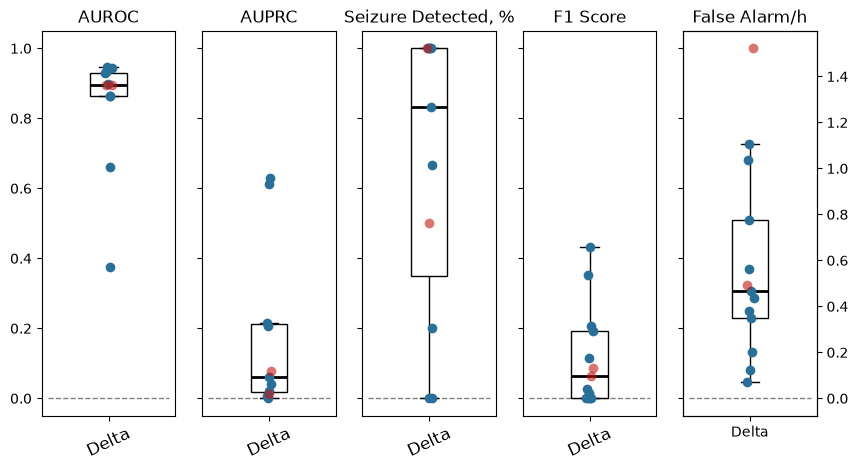

In [14]:
results_long = pd.melt(
    results,
    id_vars='patient',
    var_name="metric",        # new column with former column names
    value_name="value"           # new column with values
)
fig,ax=plot_mean_diff_overlay(results_long,sep_axis_fp=True, variables = plot_vars, ieeg=True, ieeg_col='patient')
fig.savefig(f'{out_dir}/suppfig3_baseline_performance.svg',dpi=300)

In [15]:
summary_tbl = summary(results[plot_vars])
summary_tbl.to_csv(f'{out_dir}/supp_baseline_performance_summary.csv')

### Scalp patients

In [64]:
# Aggregate scalp metrics for pickle export (no trajectory plots)
setting = '_0.5_extend_0.5'
adjth = False
calibrate = False
if calibrate:
    pred_col = 'smoothed_pred_temp'
    prob_col = 'sz_prob_temp'
else:
    pred_col = 'smoothed_pred'
    prob_col = 'sz_prob'
label_type = 'patient'  # or 'patient'
model_code = 'update_3_1.2_fix_unfreeze1'
patients = 'scalp'
if patients == 'all':
    patient_ids = patient_order.copy()
elif patients == 'scalp':
    patient_ids = [p for p in patient_order if p not in ieeg_list]
elif patients == 'ieeg':
    patient_ids = ieeg_list.copy()
else:
    patient_ids = sorted(patients.split(','))

mean_diff = []
mean_perc_diff = []
full_baseline = []
full_finetune = []
for pid in patient_ids:
    print(pid)
    meta = metadata[metadata['PID'] == pid].iloc[0]
    if meta['recording_type'] == 'Scalp':
        base_model_name = 'base_model'
    elif meta['recording_type'] == 'SEEG':
        base_model_name = 'oncet_base_model'

    baseline_pred = pd.read_csv(
        f'{data_folder}/results/{pid}/{base_model_name}/pred/{base_model_name}{setting}.csv'
    )
    model = f'{pid}_{base_model_name}_lr5e-06_wd1e-03_{label_type}_{model_code}'
    pred_files = glob.glob(f'{data_folder}/results/{pid}/{model}/pred/*{setting}.csv')
    if not pred_files:
        continue
    pred_files_df = pd.DataFrame({'filename': pred_files})
    pred_files_df['batch_ind'] = pred_files_df['filename'].apply(
        lambda x: int(os.path.basename(x).split('_')[1])
    )
    pred_files_df['adjth'] = pred_files_df['filename'].apply(lambda x: 1 if 'adjth' in x else 0)
    pred_files_df = pred_files_df.sort_values(['batch_ind', 'adjth'])
    if adjth:
        pred_files_df = pred_files_df.drop_duplicates('batch_ind', keep='last')
    else:
        pred_files_df = pred_files_df.drop_duplicates('batch_ind', keep='first')
    pred_files = pred_files_df['filename'].to_list()
    finetune_inds = pred_files_df['batch_ind'].to_list()
    finetune_inds.append(baseline_pred['batch_id'].max())

    full_pred = []
    comp_pred = []
    comp_base = []
    comp_prev = []
    full_pred.append(baseline_pred[baseline_pred['batch_id'].isin(list(range(finetune_inds[0] + 1)))])
    for i, f in enumerate(pred_files):
        pred = pd.read_csv(f)
        comp_pred.append(pred[pred['batch_id'] > finetune_inds[i]])
        comp_base.append(baseline_pred[baseline_pred['batch_id'] > finetune_inds[i]])
        if i == 0:
            comp_prev.append(baseline_pred[baseline_pred['batch_id'] > finetune_inds[i]])
        else:
            comp_prev.append(comp_pred[-1][comp_pred[-1]['batch_id'] > finetune_inds[i]])
        full_pred.append(
            pred[pred['batch_id'].isin(list(range(finetune_inds[i] + 1, finetune_inds[i + 1] + 1)))]
        )
    full_pred = pd.concat(full_pred, axis=0).sort_values(['batch_id', 'window_index'])

    baseline_metric_whole = compute_metrics(
        baseline_pred['label'].values, baseline_pred[pred_col].values, baseline_pred[prob_col].values
    )
    finetune_metric_whole = compute_metrics(
        full_pred['label'].values, full_pred[pred_col].values, full_pred[prob_col].values
    )

    comp_base_metrics = []
    comp_prev_metrics = []
    comp_finetune_metrics = []
    for base, prev, curr in zip(comp_base, comp_prev, comp_pred):
        comp_base_metrics.append(
            compute_metrics(base['label'].values, base[pred_col].values, base[prob_col].values)
        )
        comp_prev_metrics.append(
            compute_metrics(prev['label'].values, prev[pred_col].values, prev[prob_col].values)
        )
        comp_finetune_metrics.append(
            compute_metrics(curr['label'].values, curr[pred_col].values, curr[prob_col].values)
        )
    comp_base_metrics = pd.DataFrame(comp_base_metrics)
    comp_prev_metrics = pd.DataFrame(comp_prev_metrics)
    comp_finetune_metrics = pd.DataFrame(comp_finetune_metrics)

    tmp = (comp_finetune_metrics[plot_vars] - comp_base_metrics[plot_vars]).median().to_frame().T
    tmp.index = [pid]
    mean_diff.append(tmp)
    tmp = (
        (comp_finetune_metrics[plot_vars] - comp_base_metrics[plot_vars])
        / comp_base_metrics[plot_vars]
        * 100
    ).median().to_frame().T
    tmp.index = [pid]
    mean_perc_diff.append(tmp)

    baseline_tmp = pd.DataFrame([baseline_metric_whole])[plot_vars]
    baseline_tmp.index = [pid]
    full_baseline.append(baseline_tmp)
    finetune_tmp = pd.DataFrame([finetune_metric_whole])[plot_vars]
    finetune_tmp.index = [pid]
    full_finetune.append(finetune_tmp)

full_baseline = pd.concat(full_baseline)
full_finetune = pd.concat(full_finetune)
mean_diff = pd.concat(mean_diff)
mean_perc_diff = pd.concat(mean_perc_diff)
full_diff = full_finetune - full_baseline
full_perc_diff = ((full_finetune - full_baseline) / full_baseline * 100)


PID001
PID002
PID004
PID005
PID007
PID008
PID011
PID012
PID013
PID014
PID015


In [65]:
# save scalp results to concatenate with ieeg results
with open(f'{out_dir}/scalp_results_{label_type}.pkl','wb') as f:
    pickle.dump((full_baseline, full_finetune, mean_diff, mean_perc_diff, full_diff, full_perc_diff), f)


### Intracranial patients

In [59]:
# Aggregate iEEG metrics for pickle export (no trajectory plots)
setting = '_0.9_0.15'
calibrate = False
adjth = False
pred_col = 'smoothed_pred'
prob_col = 'avg_prob'
label_type = 'databricks'  # or 'databricks'
model_code = 'topk_new_update_rule_unfreeze2'
patients = 'ieeg'
patient_ids = ieeg_list.copy()
feat_setting = {'win': 1, 'stride': 1}

mean_diff = []
mean_perc_diff = []
full_baseline = []
full_finetune = []
for pid in patient_ids:
    print(pid)
    # Folders on disk use onset_base_model (not oncet)
    base_model_name = 'onset_base_model'
    base_model_pred = pd.read_csv(
        f'{data_folder}/results/{pid}/{base_model_name}/prob/{base_model_name}.csv'
    )
    model = f'{pid}_{base_model_name}_lr5e-06_wd1e-03_{label_type}_{model_code}'
    pred_files = glob.glob(f'{data_folder}/results/{pid}/{model}/prob/*.csv')
    if not pred_files:
        continue
    pred_files_df = pd.DataFrame({'filename': pred_files})
    pred_files_df['batch_ind'] = pred_files_df['filename'].apply(
        lambda x: int(os.path.basename(x).split('_')[1].replace('.csv', ''))
    )
    pred_files_df = pred_files_df.sort_values(['batch_ind'])
    pred_files = pred_files_df['filename'].to_list()
    finetune_inds = pred_files_df['batch_ind'].to_list()
    finetune_inds.append(base_model_pred['batch_id'].max())

    # Channel probs are the first half of non-meta columns (*_temp fills the second half)
    n_ch = (base_model_pred.shape[1] - 3) // 2
    prob_df = base_model_pred.iloc[:, :n_ch]
    prob = prob_df.quantile(0.8, axis=1).values
    pred, perc_chan = ieeg_get_prediction(prob_df.values)
    base_model_pred = base_model_pred[['window_index', 'batch_id', 'label']].copy()
    base_model_pred[prob_col] = prob
    base_model_pred[pred_col] = pred

    full_pred = []
    comp_pred = []
    comp_base = []
    comp_prev = []
    keep_cols = ['window_index', 'batch_id', 'label', prob_col, pred_col]
    full_pred.append(
        base_model_pred[base_model_pred['batch_id'].isin(list(range(finetune_inds[0] + 1)))][keep_cols]
    )
    for i, f in enumerate(pred_files):
        pred_df = pd.read_csv(f)
        n_ch = (pred_df.shape[1] - 3) // 2
        prob_df = pred_df.iloc[:, :n_ch]
        prob = prob_df.quantile(0.8, axis=1).values
        pred, perc_chan = ieeg_get_prediction(prob_df.values)
        pred_df = pred_df[['window_index', 'batch_id', 'label']].copy()
        pred_df[prob_col] = prob
        pred_df[pred_col] = pred
        comp_pred.append(pred_df[pred_df['batch_id'] > finetune_inds[i]])
        comp_base.append(
            base_model_pred[base_model_pred['batch_id'] > finetune_inds[i]][keep_cols]
        )
        if i == 0:
            comp_prev.append(base_model_pred[base_model_pred['batch_id'] > finetune_inds[i]])
        else:
            comp_prev.append(comp_pred[-1][comp_pred[-1]['batch_id'] > finetune_inds[i]])
        full_pred.append(
            pred_df[pred_df['batch_id'].isin(list(range(finetune_inds[i] + 1, finetune_inds[i + 1] + 1)))]
        )
    full_pred = pd.concat(full_pred, axis=0).sort_values(['batch_id', 'window_index'])

    baseline_metric_whole = compute_metrics(
        base_model_pred['label'].values,
        base_model_pred[pred_col].values,
        base_model_pred[prob_col].values,
        stride=feat_setting['stride'],
    )
    finetune_metric_whole = compute_metrics(
        full_pred['label'].values,
        full_pred[pred_col].values,
        full_pred[prob_col].values,
        stride=feat_setting['stride'],
    )

    comp_base_metrics = []
    comp_prev_metrics = []
    comp_finetune_metrics = []
    for base, prev, curr in zip(comp_base, comp_prev, comp_pred):
        comp_base_metrics.append(
            compute_metrics(
                base['label'].values, base[pred_col].values, base[prob_col].values,
                stride=feat_setting['stride'],
            )
        )
        comp_prev_metrics.append(
            compute_metrics(
                prev['label'].values, prev[pred_col].values, prev[prob_col].values,
                stride=feat_setting['stride'],
            )
        )
        comp_finetune_metrics.append(
            compute_metrics(
                curr['label'].values, curr[pred_col].values, curr[prob_col].values,
                stride=feat_setting['stride'],
            )
        )
    comp_base_metrics = pd.DataFrame(comp_base_metrics)
    comp_prev_metrics = pd.DataFrame(comp_prev_metrics)
    comp_finetune_metrics = pd.DataFrame(comp_finetune_metrics)

    tmp = (comp_finetune_metrics[plot_vars] - comp_base_metrics[plot_vars]).median().to_frame().T
    tmp.index = [pid]
    mean_diff.append(tmp)
    tmp = (
        (comp_finetune_metrics[plot_vars] - comp_base_metrics[plot_vars])
        / comp_base_metrics[plot_vars]
        * 100
    ).median().to_frame().T
    tmp.index = [pid]
    mean_perc_diff.append(tmp)

    baseline_tmp = pd.DataFrame([baseline_metric_whole])[plot_vars]
    baseline_tmp.index = [pid]
    full_baseline.append(baseline_tmp)
    finetune_tmp = pd.DataFrame([finetune_metric_whole])[plot_vars]
    finetune_tmp.index = [pid]
    full_finetune.append(finetune_tmp)

full_baseline = pd.concat(full_baseline)
full_finetune = pd.concat(full_finetune)
mean_diff = pd.concat(mean_diff)
mean_perc_diff = pd.concat(mean_perc_diff)
full_diff = full_finetune - full_baseline
full_perc_diff = ((full_finetune - full_baseline) / full_baseline * 100)

PID009
PID016


In [60]:
# save ieeg results to concatenate with scalp results
with open(f'{out_dir}/ieeg_results_{label_type}.pkl','wb') as f:
    pickle.dump((full_baseline, full_finetune, mean_diff, mean_perc_diff, full_diff, full_perc_diff), f)


### Combine scalp and ieeg results

In [66]:
for label_type in ['patient', 'databricks']:
    # save scalp results to concatenate with ieeg results
    with open(f'{out_dir}/scalp_results_{label_type}.pkl','rb') as f:
        result = pickle.load(f)
    with open(f'{out_dir}/ieeg_results_{label_type}.pkl','rb') as f:
        ieeg_result = pickle.load(f)
    
    comp_result = []
    for r, ir in zip(result,ieeg_result):
        tmp = pd.concat([r,ir])
        tmp = tmp.sort_index(key=lambda x: x.map(patient_rank))
        comp_result.append(tmp)
    
    full_baseline, full_finetune, mean_diff, mean_perc_diff, full_diff, full_perc_diff = comp_result

    full_baseline.to_csv(f'{out_dir}/supp_baseline_performance_{label_type}.csv')
    full_finetune.to_csv(f'{out_dir}/supp_full_finetune_performance_{label_type}.csv')
    mean_diff.to_csv(f'{out_dir}/supp_mean_diff_{label_type}.csv')
    mean_perc_diff.to_csv(f'{out_dir}/supp_mean_perc_diff_{label_type}.csv')
    full_diff.to_csv(f'{out_dir}/supp_full_diff_{label_type}.csv')
    full_perc_diff.to_csv(f'{out_dir}/supp_full_perc_diff_{label_type}.csv')
    
    summary(full_baseline).to_csv(f'{out_dir}/supp_summary_baseline_{label_type}.csv')
    summary(full_finetune).to_csv(f'{out_dir}/supp_summary_full_finetune_{label_type}.csv')
    summary(mean_diff).to_csv(f'{out_dir}/supp_summary_mean_diff_{label_type}.csv')
    mean_perc_diff = mean_perc_diff.replace(np.inf,0)
    mean_perc_diff = mean_perc_diff.replace(np.nan,0)
    summary(mean_perc_diff).to_csv(f'{out_dir}/supp_summary_mean_perc_diff_{label_type}.csv')
    summary(full_diff).to_csv(f'{out_dir}/supp_summary_full_diff_{label_type}.csv')
    full_perc_diff = full_perc_diff.replace(np.inf,0)
    full_perc_diff = full_perc_diff.replace(np.nan,0)
    summary(full_perc_diff).to_csv(f'{out_dir}/supp_summary_full_perc_diff_{label_type}.csv')
    

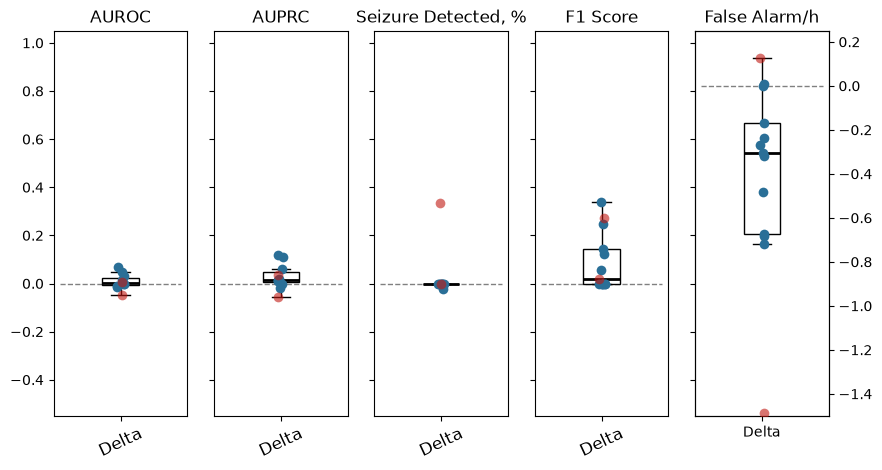

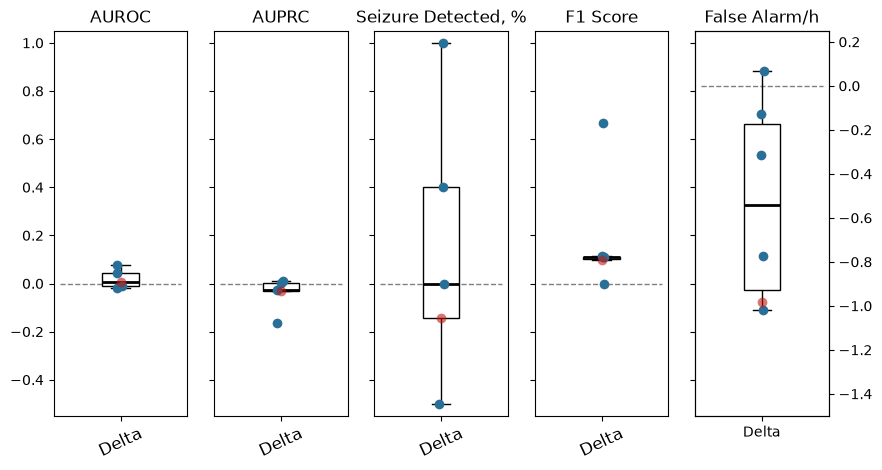

In [70]:
for label_type in ['patient', 'databricks']:
    # save scalp results to concatenate with ieeg results
    with open(f'{out_dir}/scalp_results_{label_type}.pkl','rb') as f:
        result = pickle.load(f)
    with open(f'{out_dir}/ieeg_results_{label_type}.pkl','rb') as f:
        ieeg_result = pickle.load(f)
    
    comp_result = []
    for r, ir in zip(result,ieeg_result):
        tmp = pd.concat([r,ir])
        tmp = tmp.sort_index(key=lambda x: x.map(patient_rank))
        comp_result.append(tmp)
    
    full_baseline, full_finetune, mean_diff, mean_perc_diff, full_diff, full_perc_diff = comp_result

    full_baseline['patient']=full_baseline.index
    plot_paired_line(full_baseline, full_finetune, 
                     variables=plot_vars, figsize = (10,4), save_path=f'{out_dir}/full_finetune_vs_baseline_{label_type}')
    #violin plot + scatter dots
    mean_diff = mean_diff.reset_index().rename(columns={'index':'patient'})
    results_long = pd.melt(
        mean_diff,
        id_vars='patient',
        var_name="metric",        # new column with former column names
        value_name="value"           # new column with values
    )
    fig,ax=plot_mean_diff_overlay(results_long, sep_axis_fp=True, variables = plot_vars, ieeg=True, ieeg_col='patient', ylims={'fp':[-1.5, 0.25],'f1_event':[-0.55, 1.05], 'recall_event':[-0.55, 1.05]})
    fig.savefig(f'{out_dir}/mean_diff_{label_type}.svg')

### CITL results


In [140]:
# CITL config
from pathlib import Path
from tqdm import tqdm

citl_force = True  # set True to recompute even if evaluation_metrics.csv exists
citl_dir = f'{data_folder}/citl_results'
citl_patient_ids = sorted([
    p.name for p in Path(citl_dir).iterdir()
    if p.is_dir() and p.name.startswith('PID')
])


def _has_day_stage_predictions(patient_dir: Path) -> bool:
    """True if any day*/predictions_day*_{before|after}_*.parquet exists."""
    if not patient_dir.is_dir():
        return False
    for day_dir in patient_dir.iterdir():
        if not (day_dir.is_dir() and day_dir.name.startswith('day')):
            continue
        for pq in day_dir.glob('predictions_day*_*.parquet'):
            name = pq.name
            if '_before_' in name or '_after_' in name:
                return True
    return False


# Prefer patients with day-folder stage prediction parquets (primary path)
citl_patient_ids = [
    pid for pid in citl_patient_ids
    if _has_day_stage_predictions(Path(citl_dir) / pid)
]
print(f'CITL patients with day-folder predictions: {len(citl_patient_ids)} -> {citl_patient_ids}')
citl_progression_metrics = ['auprc_sample', 'f1_event', 'fp']


CITL patients with day-folder predictions: 5 -> ['PID001', 'PID007', 'PID008', 'PID011', 'PID015']


In [141]:
def load_predictions(filepath):
    """Minimal local loader: read parquet (+ optional sidecar metadata JSON).

    Returns
    -------
    df : pd.DataFrame
        Must include at least `probability` and `true_label`.
    metadata : dict
        Sidecar JSON if present, else {}.
    """
    filepath = Path(filepath)
    df = pd.read_parquet(filepath)
    if 'probability' not in df.columns:
        raise ValueError(f"Missing 'probability' in {filepath}")
    if 'true_label' not in df.columns:
        raise ValueError(f"Missing 'true_label' in {filepath}")

    meta_path = filepath.with_name(filepath.stem + '_metadata.json')
    metadata = {}
    if meta_path.exists():
        with open(meta_path, 'r') as f:
            metadata = json.load(f)
    return df, metadata


def get_available_days(base_path):
    """Sorted list of day folder names under a patient directory."""
    if not os.path.exists(base_path):
        raise FileNotFoundError(f'Patient directory not found: {base_path}')

    days = []
    for item in os.listdir(base_path):
        item_path = os.path.join(base_path, item)
        if os.path.isdir(item_path) and item.startswith('day'):
            try:
                day_num = int(item.replace('day', ''))
                days.append((day_num, item))
            except ValueError:
                continue
    days.sort(key=lambda x: x[0])
    return [d[1] for d in days]


def sort_stage_key(stage_name):
    """Sort key: before before after, then by day number."""
    parts = stage_name.split('_')
    if len(parts) >= 2:
        timing, day_str = parts[0], parts[1]
        try:
            day_num = int(day_str.replace('day', ''))
            timing_order = 0 if timing == 'before' else 1
            return (timing_order, day_num)
        except Exception:
            return (2, 0)
    return (2, 0)


def get_tuning_stages(base_path, day_folders):
    """Detect before_*/after_* stages from prediction filenames in the first day folder."""
    if not day_folders:
        return []

    first_day_path = os.path.join(base_path, day_folders[0])
    stages = set()
    for file in os.listdir(first_day_path):
        if file.endswith('.parquet') and 'predictions' in file:
            parts = file.replace('.parquet', '').split('_')
            if len(parts) >= 3 and ('before' in parts or 'after' in parts):
                for i, part in enumerate(parts):
                    if part in ('before', 'after') and i + 1 < len(parts):
                        stages.add(f'{part}_{parts[i + 1]}')
                        break

    return sorted(stages, key=sort_stage_key)


def load_stage_predictions(base_path, day_folders, stage):
    """Load and concatenate predictions from all days for one tuning stage."""
    all_predictions = []
    for day_folder in day_folders:
        day_num = day_folder.replace('day', '')
        filename = f'predictions_day{day_num}_{stage}.parquet'
        filepath = os.path.join(base_path, day_folder, filename)
        if not os.path.exists(filepath):
            print(f'  Warning: File not found: {filepath}')
            continue
        try:
            predictions_df, _metadata = load_predictions(filepath)
            all_predictions.append(predictions_df)
        except Exception as e:
            print(f'  Error loading {filepath}: {e}')
            continue

    if not all_predictions:
        raise ValueError(f'No predictions found for stage: {stage}')
    return pd.concat(all_predictions, ignore_index=True)


def evaluate_stage(predictions_df):
    """Compute metrics for aggregated stage predictions via smooth_pred_and_extend + compute_metrics."""
    if 'true_label' not in predictions_df.columns:
        raise ValueError("predictions_df must have 'true_label' column")
    if 'probability' not in predictions_df.columns:
        raise ValueError("predictions_df must have 'probability' column")

    probs = []
    for p in predictions_df['probability'].values:
        if isinstance(p, (list, np.ndarray)):
            if len(p) > 1:
                probs.append(p[1])  # Binary: [non-seizure, seizure]
            else:
                probs.append(p[0])
        else:
            probs.append(float(p))
    prob = np.array(probs)
    true_labels = predictions_df['true_label'].values

    _, smoothed_pred = smooth_pred_and_extend(prob, return_pred=True)
    return compute_metrics(true_labels, smoothed_pred, prob)


def build_patient_evaluation_metrics(patient_id, base_dir, force=False):
    """Compute metrics for before_day1 + after_day* from day-folder parquets.
    Save to {base_dir}/{patient_id}/summary/evaluation_metrics.csv
    If not force and CSV exists, skip compute and return loaded DF.
    """
    patient_dir = os.path.join(base_dir, patient_id)
    output_dir = os.path.join(patient_dir, 'summary')
    output_csv = os.path.join(output_dir, 'evaluation_metrics.csv')

    if (not force) and os.path.exists(output_csv):
        results_df = pd.read_csv(output_csv, index_col=0)
        results_df.index.name = 'stage'
        print(f'  Loaded existing: {output_csv}')
        return results_df

    if not os.path.exists(patient_dir):
        raise FileNotFoundError(f'Patient directory not found: {patient_dir}')

    day_folders = get_available_days(patient_dir)
    tuning_stages = get_tuning_stages(patient_dir, day_folders)
    if not tuning_stages:
        raise ValueError(f'No tuning stages found for {patient_id}')

    # Match remote aggregate_metrics_by_stage filter: before_day1 + all after_dayN
    filtered_stages = [
        stage for stage in tuning_stages
        if stage == 'before_day1' or stage.startswith('after_')
    ]

    results = {}
    for stage in filtered_stages:
        try:
            predictions_df = load_stage_predictions(patient_dir, day_folders, stage)
            results[stage] = evaluate_stage(predictions_df)
            print(f'  Computed {stage}')
        except Exception as e:
            print(f'  Error on {stage}: {e}')
            continue

    if not results:
        raise ValueError(f'No stage metrics computed for {patient_id}')

    results_df = pd.DataFrame(results).T
    results_df.index.name = 'stage'
    stage_order = sorted(results_df.index.tolist(), key=sort_stage_key)
    results_df = results_df.loc[stage_order]

    os.makedirs(output_dir, exist_ok=True)
    results_df.to_csv(output_csv)
    print(f'  Wrote: {output_csv}')
    return results_df


print('CITL Step 1 helpers defined')
print('  load_predictions, get_available_days, get_tuning_stages, load_stage_predictions')
print('  evaluate_stage, build_patient_evaluation_metrics')

def load_all_patient_evaluation_metrics(patient_ids, base_dir):
    """Load stored evaluation_metrics.csv for each patient.

    Returns
    -------
    all_patient_results : dict
        {patient_id: stage_df} with stages as index
    stage_order : list
        Union of stages across patients, sorted with sort_stage_key
    """
    all_patient_results = {}
    all_stages = set()

    for patient_id in patient_ids:
        csv_path = os.path.join(base_dir, patient_id, 'summary', 'evaluation_metrics.csv')
        if not os.path.exists(csv_path):
            print(f'Warning: missing evaluation_metrics.csv for {patient_id}: {csv_path}')
            continue
        stage_df = pd.read_csv(csv_path, index_col=0)
        stage_df.index.name = 'stage'
        # Keep remote filter if older CSVs contain before_day2+
        keep = [s for s in stage_df.index if s == 'before_day1' or str(s).startswith('after_')]
        stage_df = stage_df.loc[keep]
        stage_df = stage_df.loc[sorted(stage_df.index.tolist(), key=sort_stage_key)]
        all_patient_results[patient_id] = stage_df
        all_stages.update(stage_df.index.tolist())

    stage_order = sorted(all_stages, key=sort_stage_key)
    print(f'Loaded evaluation metrics for {len(all_patient_results)} patients')
    print(f'Stages: {stage_order}')
    return all_patient_results, stage_order


def build_baseline_finetuned_from_eval(all_patient_results):
    """baseline = before_day1 (or first before), finetuned = last after_day*.

    Returns baseline_df, finetuned_df indexed by patient_id.
    """
    baseline_rows = []
    finetuned_rows = []

    for patient_id, stage_df in all_patient_results.items():
        stages = list(stage_df.index)
        baseline_stage = None
        for stage in stages:
            if 'before' in str(stage):
                baseline_stage = stage
                break
        if baseline_stage is None:
            if not stages:
                print(f'Warning: no stages for {patient_id}')
                continue
            baseline_stage = stages[0]
            print(f"Warning: No 'before' stage for {patient_id}, using {baseline_stage}")

        after_stages = [s for s in stages if str(s).startswith('after_')]
        if not after_stages:
            print(f"Warning: No 'after' stages for {patient_id}")
            continue
        last_finetuned_stage = sorted(
            after_stages, key=lambda x: int(str(x).split('_')[-1].replace('day', ''))
        )[-1]

        b = stage_df.loc[baseline_stage].to_dict()
        b['patient_id'] = patient_id
        baseline_rows.append(b)

        f = stage_df.loc[last_finetuned_stage].to_dict()
        f['patient_id'] = patient_id
        finetuned_rows.append(f)

    baseline_df = pd.DataFrame(baseline_rows).set_index('patient_id')
    finetuned_df = pd.DataFrame(finetuned_rows).set_index('patient_id')
    # Align columns/index intersection in case of heterogeneity
    shared = baseline_df.index.intersection(finetuned_df.index)
    baseline_df = baseline_df.loc[shared]
    finetuned_df = finetuned_df.loc[shared]
    print(f'Baseline/finetuned tables: {len(baseline_df)} patients')
    return baseline_df, finetuned_df


def aggregate_all_patients(patient_ids, base_dir='data/citl_results', **_kwargs):
    """Thin wrapper: load stored evaluation_metrics.csv → baseline + last after."""
    all_patient_results, _stage_order = load_all_patient_evaluation_metrics(patient_ids, base_dir)
    return build_baseline_finetuned_from_eval(all_patient_results)


def plot_paired_line_active_learning(baseline_df, finetuned_df,
                                      plot_vars=None,
                                      figsize=(15, 6), save_path=None, plot_difference=False):
    """Paired baseline vs finetuned lines (gray individuals + mean markers)."""
    if plot_vars is None:
        plot_vars = ['auroc_sample', 'auprc_sample', 'recall_event',
                     'precision_event', 'f1_event', 'fp']
    available_vars = [v for v in plot_vars if v in baseline_df.columns and v in finetuned_df.columns]
    if not available_vars:
        print('Error: None of the requested metrics found in DataFrames')
        return None

    fig, axes = plt.subplots(1, len(available_vars), sharey=True, figsize=figsize, sharex=False)
    if len(available_vars) == 1:
        axes = [axes]

    ax2 = None
    if 'fp' in available_vars:
        ax2 = axes[available_vars.index('fp')].twinx()

    for idx, var in enumerate(available_vars):
        ax = ax2 if (var == 'fp' and ax2 is not None) else axes[idx]
        if plot_difference:
            baseline_vals = np.zeros(len(baseline_df))
            finetuned_vals = finetuned_df[var].values - baseline_df[var].values
            baseline_mean = 0
            finetuned_mean = finetuned_df[var].mean() - baseline_df[var].mean()
        else:
            baseline_vals = baseline_df[var].values
            finetuned_vals = finetuned_df[var].values
            baseline_mean = baseline_df[var].mean()
            finetuned_mean = finetuned_df[var].mean()

        for i in range(len(baseline_df)):
            ax.plot([0, 1], [baseline_vals[i], finetuned_vals[i]],
                    marker='o', alpha=0.6, markersize=5, color='gray', linewidth=1)
        ax.plot([0, 1], [baseline_mean, finetuned_mean], color='k', linewidth=2)
        ax.plot([0], [baseline_mean], marker='o', markersize=10,
                markerfacecolor='white', markeredgecolor='#368899',
                markeredgewidth=1.5, color='#368899')
        ax.plot([1], [finetuned_mean], marker='o', markersize=10,
                markerfacecolor='white', markeredgecolor='#E03F67',
                markeredgewidth=1.5, color='#E03F67')
        ax.set_xticks([])
        ax.set_xticklabels([])
        if plot_difference:
            ax.set_title(f'Δ {metric_labels.get(var, var)}')
            ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5, linewidth=1)
        else:
            ax.set_title(metric_labels.get(var, var))

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path + '.svg', dpi=300, bbox_inches='tight')
        plt.savefig(save_path + '.png', dpi=300, bbox_inches='tight')
        print(f'Saved: {save_path}.svg / .png')
        plt.close(fig)
    else:
        plt.show()
    return fig


def plot_metrics_multi_patient_gray(all_patient_results, stage_order, metric_names,
                                     figsize=(15, 10), save_path=None, plot_difference=False):
    """Option 1: gray individual patients + solid mean across tuning stages."""
    sample_df = list(all_patient_results.values())[0]
    available_metrics = [m for m in metric_names if m in sample_df.columns]
    if not available_metrics:
        print('Error: None of the requested metrics found')
        return None

    n_metrics = len(available_metrics)
    n_cols = min(3, n_metrics)
    n_rows = int(np.ceil(n_metrics / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=figsize)
    if n_metrics == 1:
        axes = np.array([axes])
    axes = np.atleast_1d(axes).flatten()

    common_stages = [s for s in stage_order if s in sample_df.index]
    x_pos = np.arange(len(common_stages))

    for idx, metric in enumerate(available_metrics):
        ax = axes[idx]
        all_values = []
        for _, results_df in all_patient_results.items():
            patient_values = []
            for stage in common_stages:
                if stage in results_df.index and metric in results_df.columns:
                    val = results_df.loc[stage, metric]
                    patient_values.append(val if pd.notna(val) else np.nan)
                else:
                    patient_values.append(np.nan)
            all_values.append(patient_values)
        all_values = np.array(all_values, dtype=float)
        if plot_difference:
            all_values = all_values - all_values[:, 0:1]

        for i in range(len(all_values)):
            ax.plot(x_pos, all_values[i], marker='o', markersize=4,
                    color='gray', alpha=0.4, linewidth=1)
        mean_values = np.nanmean(all_values, axis=0)
        ax.plot(x_pos, mean_values, color='k', linewidth=2.5)
        ax.plot(x_pos, mean_values, marker='o', markersize=10, linewidth=0,
                markerfacecolor='white', markeredgecolor='#E03F67', markeredgewidth=1.5)
        ax.plot(x_pos[0], mean_values[0], marker='o', markersize=10, linewidth=0,
                markerfacecolor='white', markeredgecolor='#368899', markeredgewidth=1.5)

        xlabel_name = []
        for stage in common_stages:
            if stage == 'before_day1':
                xlabel_name.append('Baseline')
            else:
                xlabel_name.append(str(stage).replace('after_', 'After ').replace('_', ' ').title())
        ax.set_xticks(x_pos)
        ax.set_xticklabels(xlabel_name, rotation=45, ha='right', fontsize=10)
        if plot_difference:
            ax.set_title(f'Δ {metric_labels.get(metric, metric)} (from Baseline)', fontsize=12, fontweight='bold')
            ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5, linewidth=1)
        else:
            ax.set_title(metric_labels.get(metric, metric), fontsize=12, fontweight='bold')
        ax.grid(True, alpha=0.3, linestyle='--')
        if metric == 'f1_event':
            ax.set_ylim(-0.03, 0.51)

    for idx in range(n_metrics, len(axes)):
        axes[idx].axis('off')

    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], marker='o', color='gray', alpha=0.4, markersize=4,
               linewidth=1, label='Individual Patient'),
        Line2D([0], [0], color='k', linewidth=2.5, label='Average'),
        Line2D([0], [0], marker='o', color='#368899', markersize=10,
               markerfacecolor='white', markeredgecolor='#368899',
               linewidth=0, label='Baseline (avg)'),
        Line2D([0], [0], marker='o', color='#E03F67', markersize=10,
               markerfacecolor='white', markeredgecolor='#E03F67',
               linewidth=0, label='Finetuned (avg)'),
    ]
    fig.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(0.98, 0.98),
               fontsize=9, framealpha=0.9)
    if plot_difference:
        plt.suptitle(f'Metric Change from Baseline (N={len(all_patient_results)} patients)',
                     fontsize=14, fontweight='bold', y=1.02)
    else:
        plt.suptitle(f'Metric Progression Across Tuning Stages (N={len(all_patient_results)} patients)',
                     fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path + '.svg', dpi=300, bbox_inches='tight')
        plt.savefig(save_path + '.png', dpi=300, bbox_inches='tight')
        print(f'Saved: {save_path}.svg / .png')
        plt.close(fig)
    else:
        plt.show()
    return fig


print('CITL Step 2 helpers defined')
print('  load_all_patient_evaluation_metrics, build_baseline_finetuned_from_eval')
print('  aggregate_all_patients (CSV wrapper), plot_paired_line_active_learning')
print('  plot_metrics_multi_patient_gray')



CITL Step 1 helpers defined
  load_predictions, get_available_days, get_tuning_stages, load_stage_predictions
  evaluate_stage, build_patient_evaluation_metrics
CITL Step 2 helpers defined
  load_all_patient_evaluation_metrics, build_baseline_finetuned_from_eval
  aggregate_all_patients (CSV wrapper), plot_paired_line_active_learning
  plot_metrics_multi_patient_gray


In [142]:
# Step 1: build/store evaluation metrics (force or first time)
for pid in citl_patient_ids:
    print(f'{pid}:')
    try:
        build_patient_evaluation_metrics(pid, citl_dir, force=citl_force)
    except Exception as e:
        print(f'  Error: {e}')


PID001:
  Computed before_day1
  Computed after_day1
  Computed after_day2
  Computed after_day3
  Wrote: data/citl_results\PID001\summary\evaluation_metrics.csv
PID007:
  Computed before_day1
  Computed after_day1
  Computed after_day2
  Computed after_day3
  Computed after_day4
  Wrote: data/citl_results\PID007\summary\evaluation_metrics.csv
PID008:
  Computed before_day1
  Computed after_day1
  Computed after_day2
  Computed after_day3
  Computed after_day4
  Wrote: data/citl_results\PID008\summary\evaluation_metrics.csv
PID011:
  Computed before_day1
  Computed after_day1
  Computed after_day2
  Computed after_day3
  Wrote: data/citl_results\PID011\summary\evaluation_metrics.csv
PID015:
  Computed before_day1
  Computed after_day1
  Computed after_day2
  Computed after_day3
  Computed after_day4
  Wrote: data/citl_results\PID015\summary\evaluation_metrics.csv


Loaded evaluation metrics for 5 patients
Stages: ['before_day1', 'after_day1', 'after_day2', 'after_day3', 'after_day4']
Baseline/finetuned tables: 5 patients
Wrote: data/citl_results/baseline_metrics_all_patients.csv
Wrote: data/citl_results/finetuned_metrics_all_patients.csv
Wrote: data/citl_results/improvement_metrics_all_patients.csv
Wrote: data/citl_results/summary_statistics_all_metrics.csv


,auroc_sample,auprc_sample,recall_event,f1_event,fp
patient_id,,,,,
PID001,0.9237,0.5961,0.6667,0.2500,0.1492
PID007,0.6166,0.0238,0.4000,0.0606,0.5292
PID008,0.8680,0.1624,0.3333,0.0930,0.2554
PID011,0.7112,0.1194,0.5833,0.5600,0.1586
PID015,0.7034,0.0208,0.3333,0.0870,0.2101


,auroc_sample,auprc_sample,recall_event,f1_event,fp
patient_id,,,,,
PID001,0.9577,0.6361,0.6667,0.4000,0.0678
PID007,0.6630,0.0509,0.4000,0.4444,0.0179
PID008,0.8401,0.4010,0.3333,0.2857,0.0438
PID011,0.6870,0.1291,0.5417,0.6047,0.0793
PID015,0.6751,0.0702,0.3333,0.3333,0.0221


Saved: manuscript/progression_citl.svg / .png


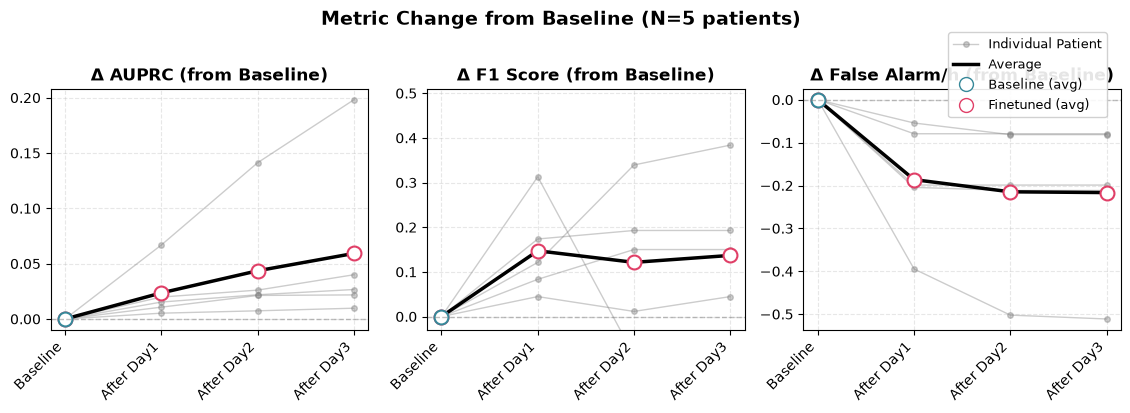

In [143]:
all_patient_results, stage_order = load_all_patient_evaluation_metrics(citl_patient_ids, citl_dir)
baseline_df, finetuned_df = build_baseline_finetuned_from_eval(all_patient_results)
improvement_df = finetuned_df - baseline_df

baseline_csv = f'{citl_dir}/baseline_metrics_all_patients.csv'
finetuned_csv = f'{citl_dir}/finetuned_metrics_all_patients.csv'
improvement_csv = f'{citl_dir}/improvement_metrics_all_patients.csv'
summary_csv = f'{citl_dir}/summary_statistics_all_metrics.csv'

baseline_df.to_csv(baseline_csv)
finetuned_df.to_csv(finetuned_csv)
improvement_df.to_csv(improvement_csv)

all_metrics = baseline_df.select_dtypes(include=[np.number]).columns.tolist()
summary_rows = []
for metric in all_metrics:
    b = baseline_df[metric].dropna()
    f = finetuned_df[metric].dropna()
    d = improvement_df[metric].dropna()
    summary_rows.append({
        'Metric': metric_labels.get(metric, metric),
        'Metric_key': metric,
        'Baseline_Mean': b.mean(),
        'Baseline_Std': b.std(),
        'Finetuned_Mean': f.mean(),
        'Finetuned_Std': f.std(),
        'Improvement_Mean': d.mean(),
        'Improvement_Std': d.std(),
        'N_Patients': len(b),
    })
summary_stats_df = pd.DataFrame(summary_rows).set_index('Metric_key')
summary_stats_df.to_csv(summary_csv)

print(f'Wrote: {baseline_csv}')
print(f'Wrote: {finetuned_csv}')
print(f'Wrote: {improvement_csv}')
print(f'Wrote: {summary_csv}')
display(baseline_df[plot_vars].round(4))
display(finetuned_df[plot_vars].round(4))

prog_save = f'{out_dir}/progression_citl'
plot_metrics_multi_patient_gray(
    all_patient_results,
    stage_order,
    metric_names=citl_progression_metrics,
    figsize=(11.5, 4),
    save_path=prog_save,
    plot_difference=True,
)


### Statistical Analysis


In [ ]:
all_mean_diff = []
all_full = []
all_full_diff = []
for label_type in ['patient', 'databricks']:
    # save scalp results to concatenate with ieeg results
    with open(f'{out_dir}/scalp_results_{label_type}.pkl','rb') as f:
        result = pickle.load(f)
    with open(f'{out_dir}/ieeg_results_{label_type}.pkl','rb') as f:
        ieeg_result = pickle.load(f)
    
    comp_result = []
    for r, ir in zip(result,ieeg_result):
        tmp = pd.concat([r,ir])
        tmp = tmp.sort_index(key=lambda x: x.map(patient_rank))
        comp_result.append(tmp)
    
    tmp_full_baseline, tmp_full_finetune, tmp_mean_diff, tmp_mean_perc_diff, tmp_full_diff, tmp_full_perc_diff = comp_result
    tmp_mean_diff['annot'] = label_type
    all_mean_diff.append(tmp_mean_diff)
    tmp_full_diff['annot'] = label_type
    all_full_diff.append(tmp_full_diff)
    tmp_full_baseline['model']='baseline'
    tmp_full_baseline['annot']=label_type
    all_full.append(tmp_full_baseline)
    tmp_full_finetune['model']='finetune'
    tmp_full_finetune['annot']=label_type
    all_full.append(tmp_full_finetune)
    
citl_baseline_df = pd.read_csv(f'{data_folder}/citl_results/baseline_metrics_all_patients.csv',index_col=0)[plot_vars]
citl_finetune_df = pd.read_csv(f'{data_folder}/citl_results/finetuned_metrics_all_patients.csv',index_col=0)[plot_vars]
citl_diff_df = pd.read_csv(f'{data_folder}/citl_results/improvement_metrics_all_patients.csv',index_col=0)[plot_vars]
summary(citl_baseline_df).to_csv(f'{out_dir}/supp_summary_baseline_citl.csv')
summary(citl_finetune_df).to_csv(f'{out_dir}/supp_summary_full_finetune_citl.csv')
summary(citl_diff_df).to_csv(f'{out_dir}/supp_summary_full_diff_citl.csv')
citl_baseline_df['model'] = 'baseline'
citl_baseline_df['annot'] = 'citl'
citl_finetune_df['model'] = 'finetune'
citl_finetune_df['annot'] = 'citl'
citl_diff_df['annot'] = 'citl'

all_full.extend([citl_baseline_df,citl_finetune_df])
all_full_diff.append(citl_diff_df)
all_full = pd.concat(all_full)   
all_full_diff = pd.concat(all_full_diff)
all_mean_diff = pd.concat(all_mean_diff)

In [85]:
from scipy import stats
def wilcoxon_one_sample_effects_and_ci(
    x,
    y=None,
    n_boot=1000,
    seed=42,
    ci=0.95,
    direction='greater'
):
    """
    diff: 1D array of paired differences (e.g. finetuned - baseline), one value per patient.
    Wilcoxon signed-rank tests H0: differences are symmetric about 0 (often used as a robust
    check on "typical" shift; interpret with median + bootstrap CI).
    """
    if y is None:
        diff = x
    else:
        diff = x-y
    diff = np.asarray(diff, dtype=float)
    diff = diff[~np.isnan(diff)]
    n = diff.size
    if n < 3:
        raise ValueError("Need at least 3 non-NaN differences for a stable Wilcoxon.")
    # zero_method='pratt' ignores pairs with diff==0 in ranking; 'wilcox' drops zeros entirely.
    wres = stats.wilcoxon(diff, alternative=direction, zero_method="wilcox",  method="auto")
    # Rank-biserial correlation (matched-pairs), common effect size for Wilcoxon in psychology/ML:
    # r_rb = sum(positive ranks - sum(negative ranks)) / sum(all ranks)
    # Implemented via signed ranks (exclude zeros for 'wilcox'-style; use pratt consistently).
    signs = np.sign(diff)
    absd = np.abs(diff)
    mask = absd > 0  # ranks only for non-zero |diff|
    ranks = stats.rankdata(absd[mask])
    sgn = signs[mask]
    sum_r_plus = ranks[sgn > 0].sum()
    sum_r_minus = ranks[sgn < 0].sum()
    denom = ranks.sum()
    r_rank_biserial = (sum_r_plus - sum_r_minus) / denom if denom > 0 else np.nan
    # Normal-approximation Z-based r (legacy "common language" effect size): r = Z / sqrt(N)
    # N here = number of signed ranks used (non-zero diffs) when using pratt/wilcox variants.
    # scipy doesn't expose Z directly; approximate from two-sided p (not ideal but sometimes reported).
    # Prefer r_rank_biserial above; we skip Z-based r to avoid misleading Z from discrete p.
    # Bootstrap CIs for mean(diff) and median(diff) — resample PATIENTS (rows).
    rng = np.random.default_rng(seed)
    alpha = 1 - ci
    boot_mean = np.empty(n_boot)
    boot_med = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        d = diff[idx]
        boot_mean[b] = d.mean()
        boot_med[b] = np.median(d)
    ci_mean = np.quantile(boot_mean, [alpha / 2, 1 - alpha / 2])
    ci_med = np.quantile(boot_med, [alpha / 2, 1 - alpha / 2])
    
#     sns.stripplot(boot_med)
#     plt.show()
    out = {
        "n_patients": int(n),
        "median_diff": float(np.median(diff)),
        "mean_diff": float(np.mean(diff)),
        "iqr_diff": tuple(np.percentile(diff, [25, 75]).astype(float)),
        "wilcoxon_statistic": float(wres.statistic),
        "wilcoxon_pvalue": float(wres.pvalue),
        "rank_biserial_r": float(r_rank_biserial),
        f"bootstrap_mean_{int(ci*100)}ci": tuple(ci_mean.astype(float)),
        f"bootstrap_median_{int(ci*100)}ci": tuple(ci_med.astype(float)),
    }
    return out


In [86]:
mean_diff_out = []
full_diff_out = []
for label_type in ['patient','databricks', 'citl']:
    for var in ['fp','f1_event']:
        if var == 'fp':
            direction = 'less'
        else:
            direction = 'greater'
        if label_type in all_mean_diff['annot'].values:
            x = all_mean_diff[all_mean_diff['annot']==label_type][var].values
            mean_diff_out.append(wilcoxon_one_sample_effects_and_ci(x,direction=direction))
        if label_type in all_full_diff['annot'].values:
            x = all_full_diff[all_full_diff['annot']==label_type][var].values
            full_diff_out.append(wilcoxon_one_sample_effects_and_ci(x,direction=direction))
mean_diff_out = pd.DataFrame(mean_diff_out)
full_diff_out = pd.DataFrame(full_diff_out)
mean_diff_out[['label_type','var']] = [(label_type, var) for label_type in ['patient','databricks'] for var in ['fp','f1_event']]
full_diff_out[['label_type','var']] = [(label_type, var) for label_type in ['patient','databricks','citl'] for var in ['fp','f1_event']]
mean_diff_out['setting'] = 'mean'
full_diff_out['setting'] = 'full'

In [87]:
x = all_full[(all_full['annot']=='patient')&(all_full['model']=='finetune')]
y = all_full[(all_full['annot']=='databricks')&(all_full['model']=='finetune')]
x = x[x.index.isin(y.index)]
label_comp_out = []
for var in ['fp','f1_event']:
    direction = 'two-sided'
    label_comp_out.append(wilcoxon_one_sample_effects_and_ci(x[var].values,y[var].values, direction=direction))
label_comp_out = pd.DataFrame(label_comp_out)
label_comp_out['var'] = ['fp','f1_event']
label_comp_out['setting'] = 'comp'
all_out = pd.concat([mean_diff_out,full_diff_out,label_comp_out])
from statsmodels.stats.multitest import multipletests
reject, pvals_bh, _, _ = multipletests(all_out['wilcoxon_pvalue'].values, alpha=0.05, method="fdr_bh")
all_out['corrected_pvalue'] = pvals_bh
all_out.to_csv(f'{out_dir}/stats.csv', index=False)

In [90]:
all_out_format = all_out.copy()
all_out_format[['median_diff','mean_diff','wilcoxon_pvalue','rank_biserial_r','corrected_pvalue']] = all_out_format[['median_diff','mean_diff','wilcoxon_pvalue','rank_biserial_r','corrected_pvalue']].round(3)
all_out_format['iqr_diff'] = all_out_format['iqr_diff'].apply(lambda x: f'[{x[0].round(3)},{x[1].round(3)}]')
all_out_format['bootstrap_mean_95ci'] = all_out_format['bootstrap_mean_95ci'].apply(lambda x: f'[{x[0].round(3)},{x[1].round(3)}]')
all_out_format['bootstrap_median_95ci'] = all_out_format['bootstrap_median_95ci'].apply(lambda x: f'[{x[0].round(3)},{x[1].round(3)}]')
all_out_format.to_csv(f'{out_dir}/stats_format.csv', index=False)

In [91]:
all_out_format

,n_patients,median_diff,mean_diff,iqr_diff,wilcoxon_statistic,wilcoxon_pvalue,rank_biserial_r,bootstrap_mean_95ci,bootstrap_median_95ci,label_type,var,setting,corrected_pvalue
0,13,-0.306,-0.401,"[-0.675,-0.168]",3.0,0.001,-0.923,"[-0.629,-0.202]","[-0.675,-0.168]",patient,fp,mean,0.007
1,13,0.017,0.092,"[0.0,0.145]",28.0,0.008,1.000,"[0.029,0.163]","[0.0,0.145]",patient,f1_event,mean,0.023
2,6,-0.543,-0.524,"[-0.93,-0.175]",1.0,0.031,-0.905,"[-0.825,-0.17]","[-1.0,-0.03]",databricks,fp,mean,0.038
3,6,0.110,0.183,"[0.101,0.112]",15.0,0.031,1.000,"[0.056,0.389]","[0.049,0.39]",databricks,f1_event,mean,0.038
0,13,-0.293,-0.414,"[-0.695,-0.141]",4.0,0.001,-0.912,"[-0.615,-0.211]","[-0.695,-0.141]",patient,fp,full,0.007
1,13,0.109,0.107,"[0.0,0.186]",45.0,0.002,1.000,"[0.055,0.153]","[0.0,0.186]",patient,f1_event,full,0.008
2,6,-0.588,-0.585,"[-0.999,-0.155]",1.0,0.031,-0.905,"[-0.942,-0.166]","[-1.147,-0.019]",databricks,fp,full,0.038
3,6,0.131,0.146,"[0.061,0.229]",15.0,0.031,1.000,"[0.065,0.229]","[0.026,0.281]",databricks,f1_event,full,0.038
4,5,-0.188,-0.214,"[-0.212,-0.081]",0.0,0.031,-1.000,"[-0.382,-0.102]","[-0.511,-0.079]",citl,fp,full,0.038
5,5,0.193,0.204,"[0.15,0.246]",15.0,0.031,1.000,"[0.106,0.31]","[0.045,0.384]",citl,f1_event,full,0.038
